In [1]:
# 1)IMPORTING LIBRARIES AND LOADING DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [23]:
df = pd.read_csv("Mobile-Price-Prediction.csv")

# Remove rows containing missing values
df = df.dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())


Dataset shape: (800, 8)
Missing values:
Ratings          0
RAM              0
ROM              0
Mobile_Size      0
Primary_Cam      0
Selfi_Cam        0
Battery_Power    0
Price            0
dtype: int64


In [24]:
# 2)SEPARATE FEATURES AND TARGET
X = df.drop("Price", axis=1).values
y = df["Price"].values.reshape(-1, 1)

print("Feature matrix shape:", X.shape)
print("Target matrix shape:", y.shape)

Feature matrix shape: (800, 7)
Target matrix shape: (800, 1)


In [25]:
# 3)TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (640, 7)
Testing data: (160, 7)


In [26]:
# 4)ADD BIAS COLUMN
X_train_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test_b = np.c_[np.ones((X_test.shape[0], 1)), X_test]

print("Training matrix:", X_train_b.shape)
print("Testing matrix:", X_test_b.shape)

Training matrix: (640, 8)
Testing matrix: (160, 8)


In [27]:
# 5)CLOSED-FORM LINEAR REGRESSION
theta_closed = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

y_pred_closed = X_test_b @ theta_closed

print("Parameter matrix:")
print(theta_closed)

Parameter matrix:
[[-9.73463553e+04]
 [ 2.44954373e+04]
 [ 2.42069761e+03]
 [ 7.95575349e+01]
 [ 1.01561002e+02]
 [-3.94605570e+02]
 [ 1.01794209e+02]
 [ 2.70577896e+00]]


In [28]:
theta_closed = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

y_pred_closed = X_test_b @ theta_closed

In [29]:
# 6)EVALUATE CLOSED-FORM MODEL
mse_closed = mean_squared_error(y_test, y_pred_closed)
rmse_closed = np.sqrt(mse_closed)
mae_closed = mean_absolute_error(y_test, y_pred_closed)
r2_closed = r2_score(y_test, y_pred_closed)

print("Closed-Form Linear Regression")
print("MAE  :", mae_closed)
print("RMSE :", rmse_closed)
print("R²   :", r2_closed)

Closed-Form Linear Regression
MAE  : 9783.913425680983
RMSE : 17512.357928459773
R²   : 0.4687530030775954


In [30]:
# 7)GRADIENT DESCENT
def gradient_descent(X, y, learning_rate=0.0000001, iterations=10000):
    
    m = len(y)
    theta = np.zeros((X.shape[1], 1))
    
    for i in range(iterations):
        predictions = X @ theta
        error = predictions - y
        
        gradient = (1/m) * (X.T @ error)
        
        theta = theta - learning_rate * gradient
    
    return theta

In [31]:
theta_gd = gradient_descent(
    X_train_b,
    y_train,
    learning_rate=0.0000001,
    iterations=10000
)

y_pred_gd = X_test_b @ theta_gd

In [32]:
# 8)EVALUATE GRADIENT DESCENT
mse_gd = mean_squared_error(y_test, y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
mae_gd = mean_absolute_error(y_test, y_pred_gd)
r2_gd = r2_score(y_test, y_pred_gd)

print("Gradient Descent")
print("MAE  :", mae_gd)
print("RMSE :", rmse_gd)
print("R²   :", r2_gd)

Gradient Descent
MAE  : 11232.883270445436
RMSE : 21070.729809504926
R²   : 0.23092907266945073


In [33]:
# 9)COMPARE CLOSED-FORM AND GRADIENT DESCENT
results = pd.DataFrame({
    "Method": ["Closed Form", "Gradient Descent"],
    "MAE": [mae_closed, mae_gd],
    "RMSE": [rmse_closed, rmse_gd],
    "R2": [r2_closed, r2_gd]
})

print(results)

             Method           MAE          RMSE        R2
0       Closed Form   9783.913426  17512.357928  0.468753
1  Gradient Descent  11232.883270  21070.729810  0.230929


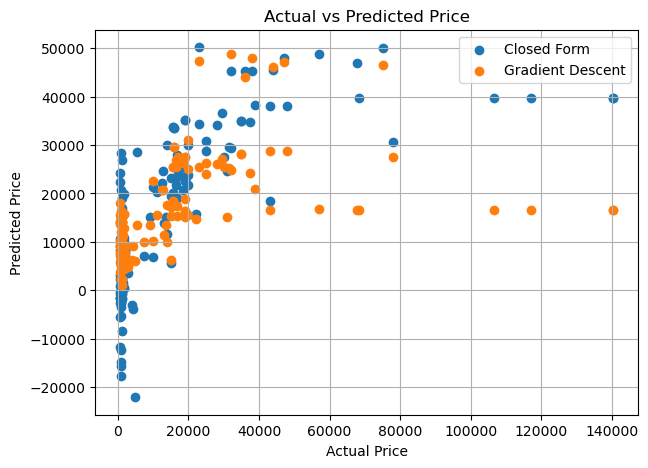

In [34]:
# 10)PLOT ACTUAL VS PREDICTED
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred_closed, label="Closed Form")
plt.scatter(y_test, y_pred_gd, label="Gradient Descent")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.legend()
plt.grid(True)

plt.show()

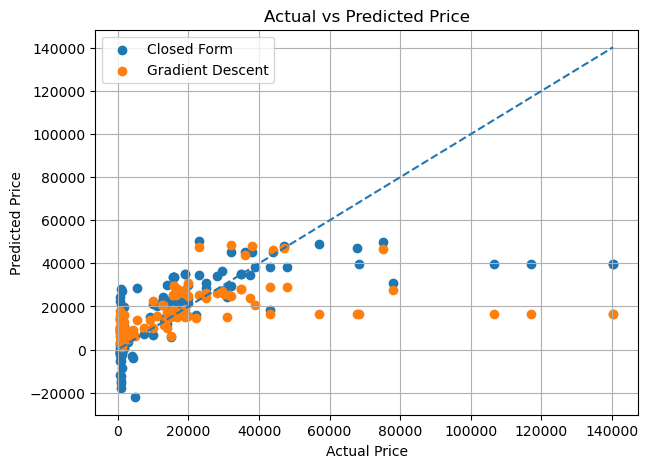

In [35]:
#REFERENCE LINE
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred_closed, label="Closed Form")
plt.scatter(y_test, y_pred_gd, label="Gradient Descent")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
# 11)L2 REGULARIZATION-RIDGE REGRESSION
def ridge_closed_form(X, y, lam):
    
    I = np.eye(X.shape[1])
    
    # Do not regularize bias
    I[0, 0] = 0
    
    theta = np.linalg.pinv(
        X.T @ X + lam * I
    ) @ X.T @ y
    
    return theta

In [37]:
lam = 1

theta_ridge = ridge_closed_form(
    X_train_b,
    y_train,
    lam
)

y_pred_ridge = X_test_b @ theta_ridge

In [38]:
print("L2 Regularized Model")

print("MAE :", mean_absolute_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("R²  :", r2_score(y_test, y_pred_ridge))

L2 Regularized Model
MAE : 9759.55711802423
RMSE: 17523.33088228056
R²  : 0.4680870533436715


In [39]:
# 12)L2 GRADIENT DESCENT
def ridge_gradient_descent(X, y, learning_rate=0.0001,
                           iterations=10000, lam=1):
    
    m = len(y)
    theta = np.zeros((X.shape[1], 1))
    
    for i in range(iterations):
        
        predictions = X @ theta
        error = predictions - y
        
        gradient = (1/m) * (X.T @ error)
        
        # Do not regularize bias
        regularization = (lam/m) * theta
        regularization[0] = 0
        
        theta = theta - learning_rate * (
            gradient + regularization
        )
    
    return theta

In [40]:
# 13)STANDARDIZATION
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

X_train_std_b = np.c_[
    np.ones((X_train_std.shape[0], 1)),
    X_train_std
]

X_test_std_b = np.c_[
    np.ones((X_test_std.shape[0], 1)),
    X_test_std
]

In [41]:
# 14)L2 GRADIENT DESCENT WITH STANDARDIZATION
theta_ridge_gd = ridge_gradient_descent(
    X_train_std_b,
    y_train,
    learning_rate=0.01,
    iterations=10000,
    lam=1
)

y_pred_ridge_gd = X_test_std_b @ theta_ridge_gd

In [42]:
print("L2 Gradient Descent with Standardization")

print("MAE :",
      mean_absolute_error(y_test, y_pred_ridge_gd))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_ridge_gd)))

print("R²  :",
      r2_score(y_test, y_pred_ridge_gd))

L2 Gradient Descent with Standardization
MAE : 9780.575545638863
RMSE: 17514.05897050114
R²  : 0.46864979397595063


In [43]:
# 15) COMPARE L2 WITH AND WITHOUT STANDARDIZATION
# L2 without standardization
theta_unstd = ridge_closed_form(X_train_b, y_train, 1)
pred_unstd = X_test_b @ theta_unstd

# L2 with standardization
theta_std = ridge_closed_form(X_train_std_b, y_train, 1)
pred_std = X_test_std_b @ theta_std

comparison = pd.DataFrame({
    "Model": [
        "L2 Without Standardization",
        "L2 With Standardization"
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_unstd),
        mean_absolute_error(y_test, pred_std)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_unstd)),
        np.sqrt(mean_squared_error(y_test, pred_std))
    ],
    "R2": [
        r2_score(y_test, pred_unstd),
        r2_score(y_test, pred_std)
    ]
})

print(comparison)


                        Model          MAE          RMSE        R2
0  L2 Without Standardization  9759.557118  17523.330882  0.468087
1     L2 With Standardization  9780.575546  17514.058971  0.468650


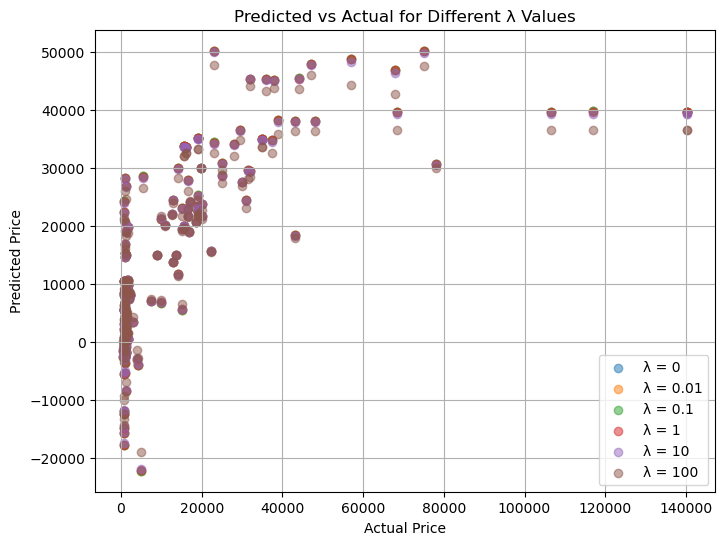

In [44]:
# 16)TEST DIFFERENT LAMBDA VALUES
lambda_values = [0, 0.01, 0.1, 1, 10, 100]
plt.figure(figsize=(8,6))

for lam in lambda_values:
    
    theta = ridge_closed_form(
        X_train_std_b,
        y_train,
        lam
    )
    
    prediction = X_test_std_b @ theta
    
    plt.scatter(
        y_test,
        prediction,
        label=f"λ = {lam}",
        alpha=0.5
    )

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual for Different λ Values")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
# 17)COMPARE LAMBDA VALUES NUMERICALLY
lambda_results = []

for lam in lambda_values:
    
    theta = ridge_closed_form(
        X_train_std_b,
        y_train,
        lam
    )
    
    prediction = X_test_std_b @ theta
    
    rmse = np.sqrt(
        mean_squared_error(y_test, prediction)
    )
    
    r2 = r2_score(y_test, prediction)
    
    lambda_results.append([lam, rmse, r2])

lambda_table = pd.DataFrame(
    lambda_results,
    columns=["Lambda", "RMSE", "R2"]
)

print(lambda_table)

   Lambda          RMSE        R2
0    0.00  17512.357929  0.468753
1    0.01  17512.374893  0.468752
2    0.10  17512.527616  0.468743
3    1.00  17514.058971  0.468650
4   10.00  17529.767259  0.467696
5  100.00  17713.319844  0.456490


In [46]:
# 18)FEATURE IMPORTANCE FROM L2 WEIGHTS
features = df.drop("Price", axis=1).columns

weights = theta_std[1:].flatten()

importance = pd.DataFrame({
    "Feature": features,
    "Weight": weights,
    "Absolute Weight": np.abs(weights)
})

importance = importance.sort_values(
    "Absolute Weight",
    ascending=False
)

print(importance)

         Feature       Weight  Absolute Weight
0        Ratings  8975.628331      8975.628331
1            RAM  4974.773595      4974.773595
4    Primary_Cam -4416.828004      4416.828004
2            ROM  4274.107392      4274.107392
6  Battery_Power  2546.475467      2546.475467
5      Selfi_Cam   460.107036       460.107036
3    Mobile_Size   360.871057       360.871057


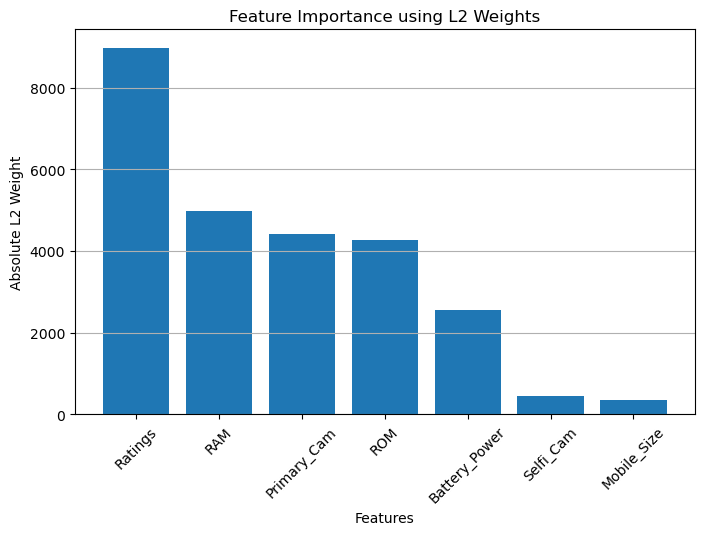

In [47]:
# 19)FEATURE IMPORTANCE GRAPH
plt.figure(figsize=(8,5))

plt.bar(
    importance["Feature"],
    importance["Absolute Weight"]
)

plt.xlabel("Features")
plt.ylabel("Absolute L2 Weight")
plt.title("Feature Importance using L2 Weights")

plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [48]:
# 20) FINAL COMPARISON TABLE:
final_results = pd.DataFrame({
    "Model": [
        "Linear Regression - Closed Form",
        "Linear Regression - Gradient Descent",
        "L2 - Closed Form",
        "L2 - Gradient Descent"
    ],
    
    "RMSE": [
        rmse_closed,
        rmse_gd,
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_gd))
    ],
    
    "MAE": [
        mae_closed,
        mae_gd,
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_ridge_gd)
    ],
    
    "R2": [
        r2_closed,
        r2_gd,
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_ridge_gd)
    ]
})

print(final_results)

                                  Model          RMSE           MAE        R2
0       Linear Regression - Closed Form  17512.357928   9783.913426  0.468753
1  Linear Regression - Gradient Descent  21070.729810  11232.883270  0.230929
2                      L2 - Closed Form  17523.330882   9759.557118  0.468087
3                 L2 - Gradient Descent  17514.058971   9780.575546  0.468650
